**LIMPIEZA Y PREPROCESAMIENTO DE LOS DATOS**

En primer lugar, importamos las librerías necesarias (`pandas` y `numpy`), definimos las rutas de entrada y salida, y cargamos el dataset original (`cardio_train.csv`) separado por punto y coma (`;`) ademas usamos (`.shape`) para comprobar sus dimensiones iniciales.

In [31]:
import pandas as pd
import numpy as np

#rutas
input="../data/raw/cardio_train.csv"
output="../data/processed/cardio_train_clean.csv"

#lecturas
data=pd.read_csv(input, sep=";")
print(data.shape)

(70000, 13)


**1. Eliminación de duplicados**

Comprobamos si existen filas duplicadas en el conjunto de datos y las eliminamos. Esto es importante para evitar que registros repetidos generen errores al realizar los posteriores analisis y graficas.

In [32]:
'''#eliminacion de duplicados
duplicados= data.duplicated().sum()
data.drop_duplicates(inplace=True)
print(f"{duplicados} removed")'''

'#eliminacion de duplicados\nduplicados= data.duplicated().sum()\ndata.drop_duplicates(inplace=True)\nprint(f"{duplicados} removed")'

In [33]:
#eliminacion de duplicados
duplicados= data.drop(columns="id").duplicated().sum()
data.drop_duplicates(inplace=True)
print(f"{duplicados} removed")

24 removed


**2. Conversión de la edad a años**

En el dataset original la variable `age` viene expresada en días. La dividimos entre `365.25` (teniendo en cuenta los años bisiestos) y la convertimos a número entero para trabajar con la edad en años, que es mucho más interpretable.

In [34]:
#edad a años
data["age"]=(data["age"]/365.25).astype(int)
print(data["age"].iloc[0])

50


**3. Primer filtrado de valores extremos o errores de registro (variables continuas)**

Filtramos valores biológicamente improbables o producidos por errores de introducción de datos en variables numéricas:
- **Altura (`height`)**: mayor de 100 cm.
- **Peso (`weight`)**: mayor de 30 kg.
- **Edad (`age`)**: menor de 110 años.
- **Presión arterial sistólica (`ap_hi`)**: entre 50 y 250 mmHg.
- **Presión arterial diastólica (`ap_lo`)**: entre 30 y 150 mmHg.

De esta forma eliminamos *outliers* irreales (como presiones negativas o de miles de mmHg) que distorsionarían las medias y gráficas.

In [35]:
#primer filtrado de posibles errores 
antes=data.shape[0]

data=data[(data["height"]>100) & (data["weight"]>30) & (data["height"]<220) & (data["weight"]<200) & (data["age"]<110) & (data["ap_hi"]>=50) 
          & (data["ap_hi"]<=250) & (data["ap_lo"]>=30) & (data["ap_lo"]<=150)]

elim= antes- data.shape[0]
print(f"{elim} removed")

1280 removed


**4. Limpieza de variables categóricas**

Verificamos que todas las variables categóricas y binarias contengan únicamente los códigos válidos definidos en la descripcción del dataset de kaggel:
- `cholesterol` y `gluc`: valores `1` (normal), `2` (alto) o `3` (muy alto).
- `smoke`, `alco`, `active` y `cardio`: valores binarios `0` (no/sano) o `1` (sí/enfermo).

Así garantizamos la integridad de las categorías antes de agrupar o graficar.

In [36]:
#limpieza de datos categoricos
antes2= data.shape[0]

data=data[(data["cholesterol"].isin([1, 2, 3])) & (data["gluc"].isin([1,2,3]))
          & (data["smoke"].isin([0,1])) & (data["alco"].isin([0,1])) & (data["active"].isin([0,1]))
          & (data["cardio"].isin([0,1]))]

elim2= antes2- data.shape[0]
print(f" {elim2} removed")

 0 removed


**5. Coherencia fisiológica en la presión arterial**

Eliminamos los registros en los que la presión diastólica (`ap_lo`, baja) sea mayor o igual que la presión sistólica (`ap_hi`, alta), ya que fisiológicamente no es posible y corresponde a un error de medición o transcripción.

In [37]:
#elimiacion diastolica > sistolica (no es posible)
antes3= data.shape[0]
data=data[data["ap_hi"]>data["ap_lo"]]
elim3= antes3-data.shape[0]
print(f"{elim3} removed")

88 removed


**6. Eliminación de valores nulos**

Contabilizamos y eliminamos cualquier fila que tenga valores faltantes (`NaN`), asegurando que el dataset final esté completo y no produzca errores en los cálculos posteriores.

In [38]:
#elimiacion de nulos
antes4=data.shape[0]
nulos= data.isnull().sum().sum()
data.dropna(inplace=True)
elim4=antes4- data.shape[0]
print(f"{nulos} nulos eliminados de {elim4} filas")

0 nulos eliminados de 0 filas


**7. Cálculo del Índice de Masa Corporal (IMC / BMI) y exportación**

Creamos una nueva variable `bmi` (Índice de Masa Corporal) a partir del peso en kg y la altura en metros ($\text{IMC} = \frac{\text{peso}}{\text{altura}^2}$), redondeada a un decimal. Esta variable sintetiza la relación peso-altura y es un indicador clave de riesgo cardiovascular. Finalmente, guardamos el dataset limpio en `data/processed/cardio_train_clean.csv`.

In [39]:
#imc
data["bmi"]=(data["weight"]/((data["height"]/100)**2)).round(1)

#exportacion
data.to_csv(output, index=False)

**ANALISIS DE LOS DATOS**

In [40]:
import pandas as pd
import matplotlib.pyplot as plt

datos=pd.read_csv("../data/processed/cardio_train_clean.csv", sep=",")


**Grafico del balance sanos enfermos**

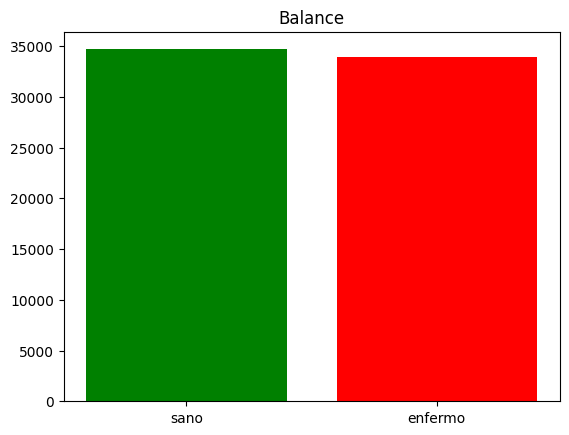

In [41]:
conteo= datos["cardio"].value_counts()
plt.bar((["sano", "enfermo"]), conteo.values, color=["green", "red"])
plt.title("Balance")
plt.show()

En esta tabla comparamos la presión arterial media de cada grupo. Los pacientes enfermos tienen una presión sistólica media de unos 134 mmHg frente a los 120 mmHg de los sanos, y una diastólica de unos 84.5 mmHg frente a 78 mmHg. Es decir, el grupo con enfermedad cardiovascular tiene la presión más alta en las dos medidas, lo que encaja con que la hipertensión es un factor de riesgo cardiovascular.

**Media de presion arterial**

In [42]:
print(datos.groupby("cardio")[["ap_hi", "ap_lo"]].mean())

             ap_hi      ap_lo
cardio                       
0       119.604129  78.121258
1       133.890558  84.542057


En esta tabla comparamos la presión arterial media de cada grupo. Los pacientes enfermos tienen una presión sistólica media de unos 134 mmHg frente a los 120 mmHg de los sanos, y una diastólica de unos 84.5 mmHg frente a 78 mmHg. Es decir, el grupo con enfermedad cardiovascular tiene la presión más alta en las dos medidas, lo que encaja con que la hipertensión es un factor de riesgo cardiovascular.

**Mapa de corrrelación**

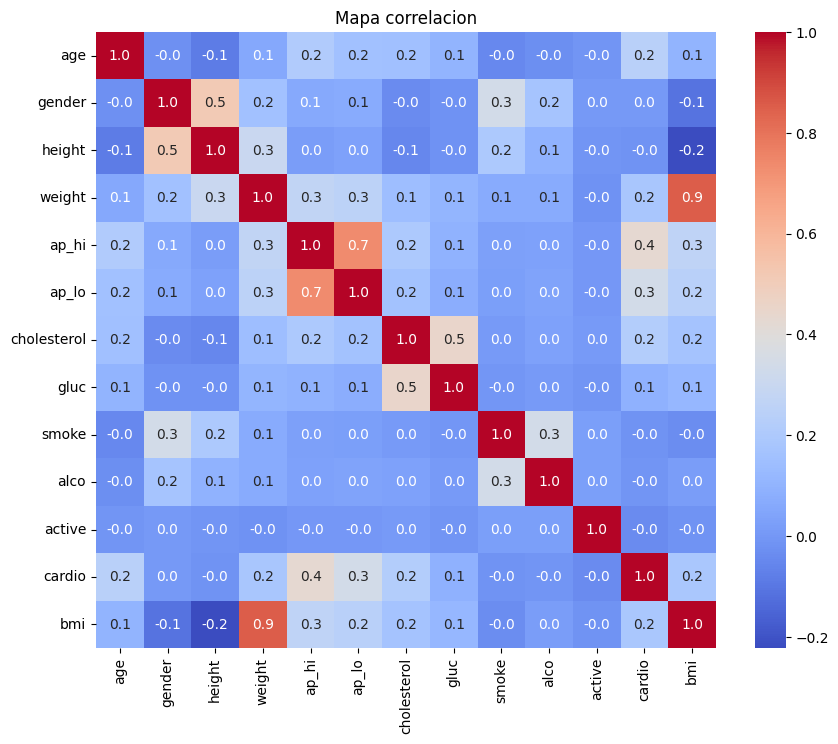

In [43]:
import seaborn as sns

plt.figure(figsize=(10,8))
corr=datos.drop("id", axis=1).corr()
sns.heatmap(corr, annot=True, fmt=".1f", cmap="coolwarm")
plt.title("Mapa correlacion")
plt.show()

El mapa de calor muestra la correlación entre todas las variables numéricas. Nos fijamos sobre todo en la fila de `cardio`: la presión arterial (`ap_hi` y `ap_lo`) es la variable más relacionada con la enfermedad, seguida de la edad, el colesterol y el IMC, aunque ninguna correlación es muy fuerte. También vemos que `ap_hi` y `ap_lo` están muy correlacionadas entre sí, y que el peso lo está con el IMC, algo lógico porque el IMC se calcula a partir del peso. Variables como `smoke`, `alco` o `active` casi no se relacionan con `cardio`.

**Riesgo segun colesterol**

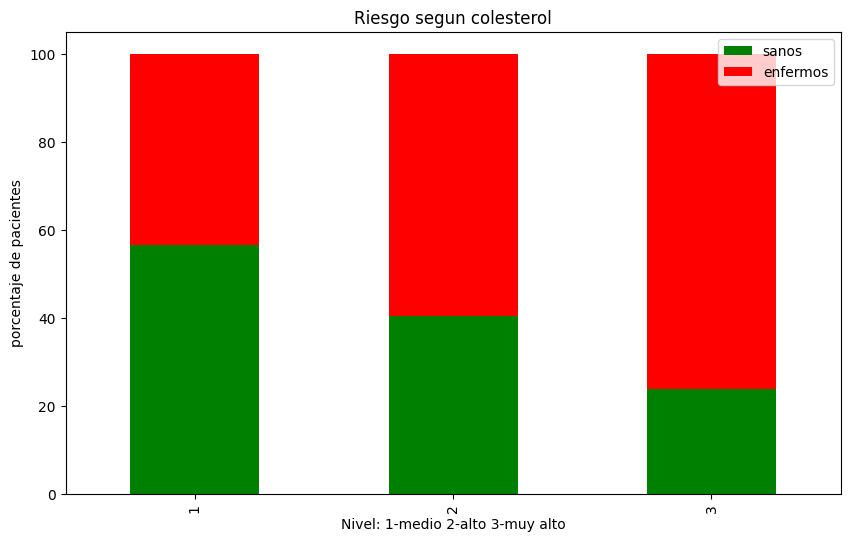

In [44]:
colper.plot(kind="bar", stacked=True, color=["green", "red"], figsize=(10,6))
plt.title("Riesgo segun colesterol")
plt.xlabel("Nivel: 1-medio 2-alto 3-muy alto")
plt.ylabel("porcentaje de pacientes")
plt.legend(["sanos", "enfermos"])
plt.show()

In [45]:
colper= pd.crosstab(datos["cholesterol"], datos["cardio"], normalize="index")*100
print(colper)

cardio               0          1
cholesterol                      
1            56.456439  43.543561
2            40.374274  59.625726
3            23.735062  76.264938


Este gráfico de barras apiladas muestra, para cada nivel de colesterol, el porcentaje de pacientes sanos y enfermos. Con colesterol normal (nivel 1) el 43.5 % de los pacientes tiene enfermedad cardiovascular, con colesterol alto (nivel 2) sube al 59.6 % y con colesterol muy alto (nivel 3) llega al 76.3 %. Por tanto, cuanto mayor es el nivel de colesterol, mayor es la proporción de pacientes enfermos, así que parece un factor de riesgo importante.

**Relación IMC - enfermedad**

C:\Users\Lucia\AppData\Local\Temp\ipykernel_23444\1672532379.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([sanos, enfermos], labels=["sanos", "enfermos"])


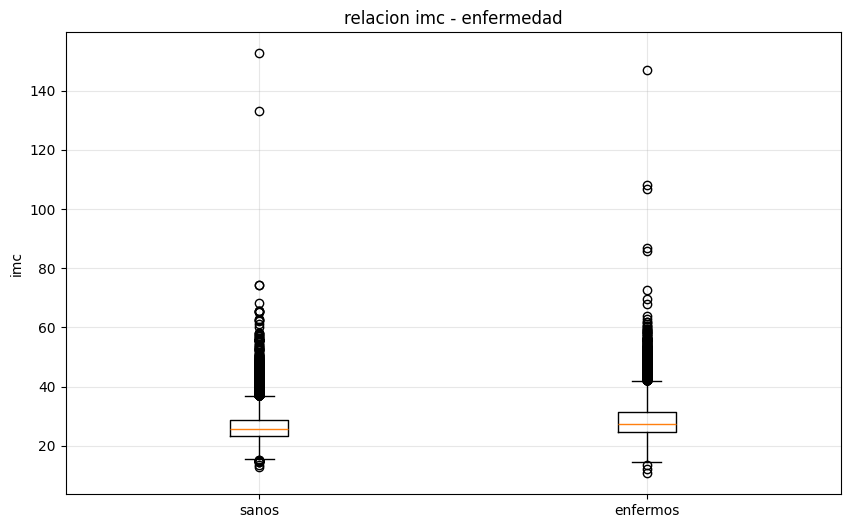

In [46]:
plt.figure(figsize=(10,6))
sanos=datos[datos["cardio"]==0]["bmi"]
enfermos=datos[datos["cardio"]==1]["bmi"]

plt.boxplot([sanos, enfermos], labels=["sanos", "enfermos"])
plt.title("relacion imc - enfermedad")
plt.ylabel("imc")
plt.grid(True, alpha=0.3)
plt.show()

En el diagrama de cajas comparamos la distribución del IMC de los pacientes sanos y enfermos. La mediana y la caja de los enfermos están algo más arriba, lo que indica que tienden a tener un IMC más alto, es decir, más sobrepeso. La diferencia no es muy grande y las dos distribuciones se solapan bastante, por lo que el IMC por sí solo no basta para distinguir a un paciente sano de uno enfermo. 

**Grafico interactivo**

In [47]:
import plotly.express as px

datos["enfermedad"] = datos["cardio"].map({0: "Sano", 1: "Enfermo"})

fig = px.histogram(datos, x="ap_hi", color="enfermedad", barmode="overlay",
                   nbins=50, opacity=0.6,
                   labels={"ap_hi": "Presión sistólica (mmHg)", "enfermedad": "Estado"},
                   title="Distribución de la presión sistólica según enfermedad")
fig.show()

Con este histograma interactivo comparamos cómo se distribuye la presión sistólica en sanos y enfermos (al pasar el ratón por las barras se ve el número de pacientes de cada intervalo). La mayoría de los pacientes sanos se concentra en torno a 120 mmHg, mientras que en los enfermos la distribución está desplazada hacia valores más altos, con más pacientes por encima de 140 mmHg. Esto confirma de forma visual lo que veíamos en las medias: la presión sistólica elevada se asocia con tener enfermedad cardiovascular.

In [48]:
from dash import Dash, dcc, html, Input, Output
import plotly.express as px

app = Dash(__name__)

app.layout = html.Div([
    html.H1("Dashboard cardiovascular"),
    dcc.Dropdown(
        id="variable",
        options=["cholesterol", "gluc", "smoke", "alco", "active"],
        value="cholesterol",
        clearable=False,
    ),
    dcc.Graph(id="grafico_riesgo"),
    dcc.Graph(id="grafico_edad"),
])

@app.callback(
    Output("grafico_riesgo", "figure"),
    Output("grafico_edad", "figure"),
    Input("variable", "value"),
)
def actualizar(variable):
    porcentaje = (datos.groupby(variable)["cardio"].mean() * 100).reset_index()
    fig1 = px.bar(porcentaje, x=variable, y="cardio",
                  labels={"cardio": "% con enfermedad"},
                  title=f"Riesgo según {variable}")
    fig2 = px.histogram(datos, x="age", color=variable, barmode="overlay",
                        title=f"Edad según {variable}")
    return fig1, fig2

app.run(jupyter_mode="inline", debug=True)